In [1]:
print("Hello! My Datheon internship project has started.")

Hello! My Datheon internship project has started.


In [ ]:
import pandas as pd


df = pd.read_csv("iris.csv")


print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nFlower species:")
print(df["species"].value_counts())

Dataset shape: (150, 5)

Column names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

First five rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Flower species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [ ]:

print("Dataset information:")
df.info()


print("\nMissing values in each column:")
print(df.isnull().sum())


print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Missing values in each column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Number of duplicate rows:
1

Statistical summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


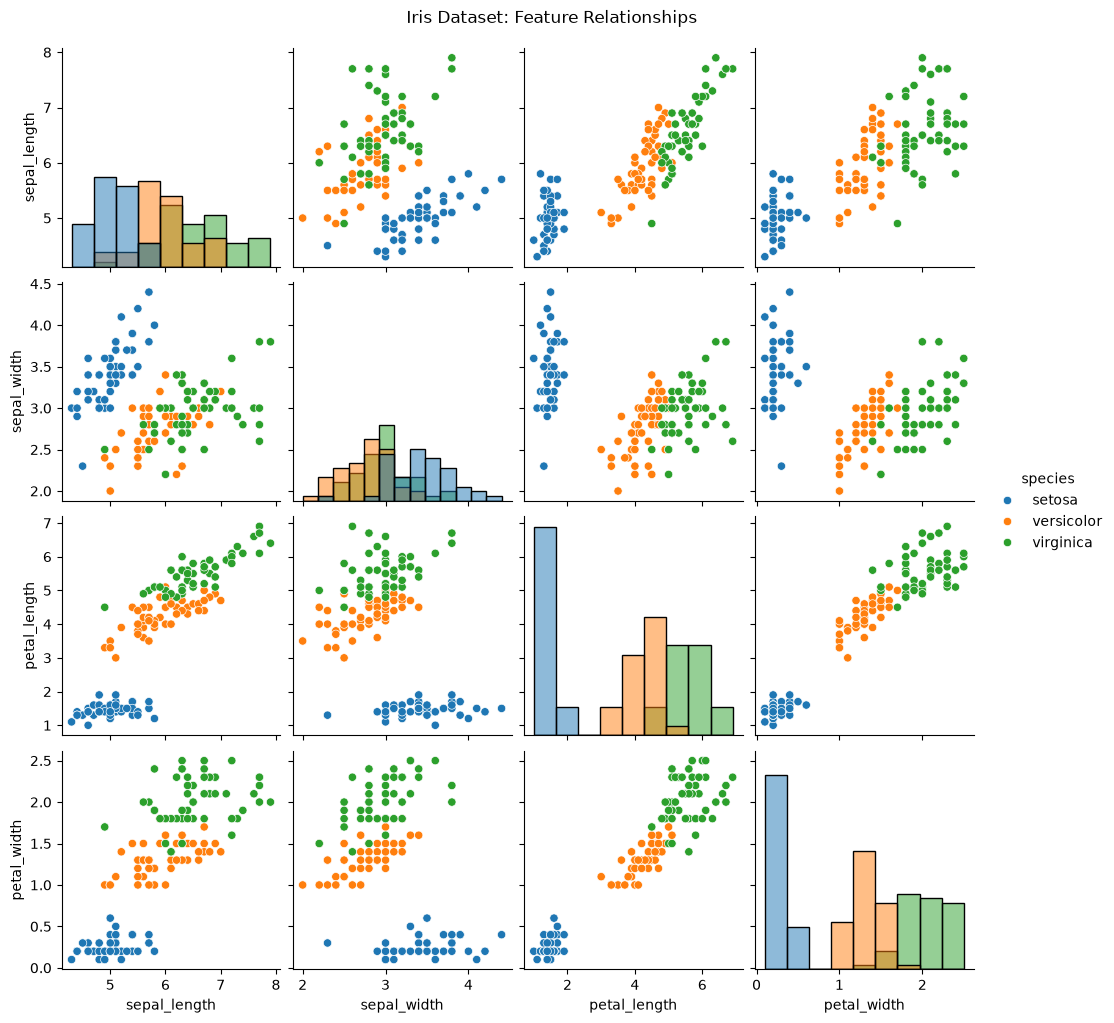

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.pairplot(df, hue="species", diag_kind="hist")

plt.suptitle("Iris Dataset: Feature Relationships", y=1.02)
plt.show()

In [ ]:

X = df.drop(columns=["species"])


y = df["species"]

print("Features (X):")
display(X.head())

print("\nTarget labels (y):")
display(y.head())

print("\nNumber of features:", X.shape[1])
print("Number of samples:", X.shape[0])
print("Number of classes:", y.nunique())

Features (X):


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target labels (y):


0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str


Number of features: 4
Number of samples: 150
Number of classes: 3


In [ ]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 120
Testing samples: 30

Training features shape: (120, 4)
Testing features shape: (30, 4)

Training class distribution:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing class distribution:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)


X_test_scaled = scaler.transform(X_test)

print("Original training data:")
display(X_train.head())

print("\nScaled training data (first five rows):")
display(pd.DataFrame(
    X_train_scaled,
    columns=X.columns
).head())

print("\nScaling completed successfully!")

Original training data:


,sepal_length,sepal_width,petal_length,petal_width
8,4.4,2.9,1.4,0.2
106,4.9,2.5,4.5,1.7
76,6.8,2.8,4.8,1.4
9,4.9,3.1,1.5,0.1
89,5.5,2.5,4.0,1.3



Scaled training data (first five rows):


,sepal_length,sepal_width,petal_length,petal_width
0,-1.721568,-0.332101,-1.345722,-1.323276
1,-1.124492,-1.227655,0.414505,0.651763
2,1.144395,-0.555990,0.584850,0.256755
3,-1.124492,0.115676,-1.288941,-1.454945
4,-0.408002,-1.227655,0.130598,0.125086



Scaling completed successfully!


In [ ]:
from sklearn.linear_model import LogisticRegression


logistic_model = LogisticRegression(max_iter=1000)


logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
from sklearn.tree import DecisionTreeClassifier


tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)


tree_model.fit(X_train_scaled, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:

y_pred_logistic = logistic_model.predict(X_test_scaled)


y_pred_tree = tree_model.predict(X_test_scaled)

print("Actual flower species:")
print(y_test.tolist())

print("\nLogistic Regression predictions:")
print(y_pred_logistic.tolist())

print("\nDecision Tree predictions:")
print(y_pred_tree.tolist())

Actual flower species:
['setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'virginica', 'versicolor', 'setosa', 'setosa', 'setosa', 'versicolor', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica', 'setosa']

Logistic Regression predictions:
['setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'virginica', 'versicolor', 'setosa', 'setosa', 'setosa', 'versicolor', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'versicolor', 'virginica', 'virginica', 'versicolor', 'setosa', 'virginica', 'setosa']

Decision Tree predictions:
['setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'virginica', 'virginica', 'virginica', 'versicolor

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd


models_predictions = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree
}

results = []

for model_name, predictions in models_predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


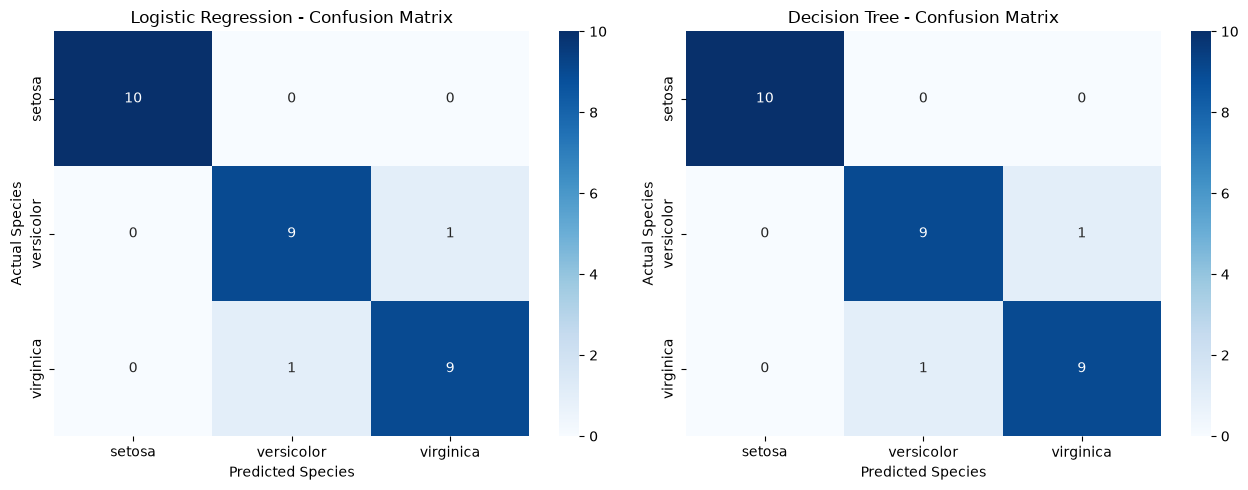

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (model_name, predictions) in zip(
    axes, models_predictions.items()
):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=logistic_model.classes_
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=logistic_model.classes_,
        yticklabels=logistic_model.classes_,
        ax=ax
    )

    ax.set_title(f"{model_name} - Confusion Matrix")
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

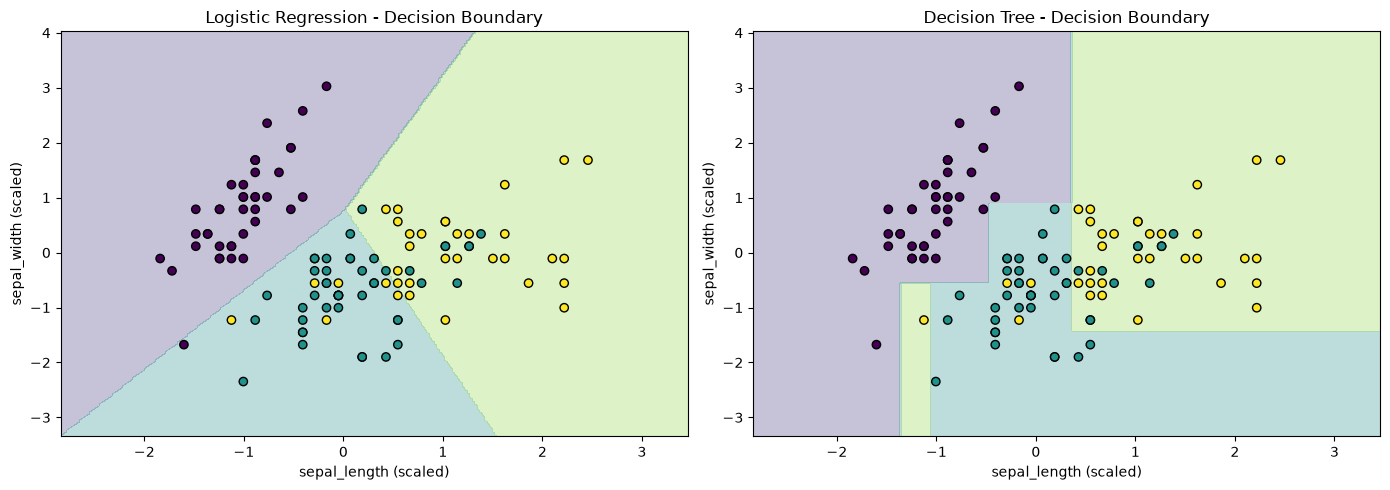

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier


X_2d = X.iloc[:, :2]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y, test_size=0.20, random_state=42, stratify=y
)


scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)


logistic_2d = LogisticRegression(max_iter=1000)
tree_2d = DecisionTreeClassifier(max_depth=4, random_state=42)

logistic_2d.fit(X_train_2d_scaled, y_train_2d)
tree_2d.fit(X_train_2d_scaled, y_train_2d)


class_names = list(logistic_2d.classes_)
class_mapping = {name: i for i, name in enumerate(class_names)}
y_train_numeric = np.array([class_mapping[label] for label in y_train_2d])


x_min = X_train_2d_scaled[:, 0].min() - 1
x_max = X_train_2d_scaled[:, 0].max() + 1
y_min = X_train_2d_scaled[:, 1].min() - 1
y_max = X_train_2d_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)
grid = np.c_[xx.ravel(), yy.ravel()]


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, name in zip(
    axes,
    [logistic_2d, tree_2d],
    ["Logistic Regression", "Decision Tree"]
):
    predictions = model.predict(grid)
    Z = np.array([class_mapping[label] for label in predictions])
    Z = Z.reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        levels=np.arange(len(class_names) + 1) - 0.5,
        alpha=0.3,
        cmap="viridis"
    )

    ax.scatter(
        X_train_2d_scaled[:, 0],
        X_train_2d_scaled[:, 1],
        c=y_train_numeric,
        cmap="viridis",
        edgecolors="black"
    )

    ax.set_title(f"{name} - Decision Boundary")
    ax.set_xlabel(f"{X.columns[0]} (scaled)")
    ax.set_ylabel(f"{X.columns[1]} (scaled)")

plt.tight_layout()
plt.show()


In [ ]:

results_df.to_csv("model_comparison.csv", index=False)


df.to_csv("iris_dataset.csv", index=False)

print("Results saved successfully!")
print("\nModel Comparison:")
display(results_df.round(4))

Results saved successfully!

Model Comparison:


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333
